# 03 — Delayed Labels Simulation & Rolling Evaluation

**Project**: UPI Fraud Detection — Drift-Aware Explainable ML Framework
**Goal**: Simulate delayed fraud labels (1/7/30-day), evaluate with rolling windows, compare vs oracle

In [30]:
# Setup
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path
import joblib

from data_prep import load_ieee_cis, load_paysim, prepare_features_target, handle_class_imbalance
from models import get_model, train_model, evaluate_model, rolling_time_cv, train_all_baselines
from drift_detection import DriftMonitor

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

DATA_ROOT = Path('../data')
MODELS_DIR = Path('../models')
REPORTS_DIR = Path('../reports')
REPORTS_DIR.mkdir(exist_ok=True)

print(f"Data root: {DATA_ROOT.absolute()}")

Data root: /Users/pavanc/Downloads/UPI_Fraud_Detection_Project/notebooks/../data


## 1. Load Data & Best Model

In [31]:
# Load IEEE-CIS test data
ieee_split_dir = DATA_ROOT / 'ieee-cis' / 'splits'
test_ieee = pd.read_parquet(ieee_split_dir / 'test.parquet')
print(f"IEEE-CIS test: {test_ieee.shape}")

# Apply feature engineering
def apply_fe(df, name):
    df = df.copy()
    if name == 'ieee-cis':
        df['hour'] = (df['TransactionDT'] // 3600) % 24
        df['day_of_week'] = (df['TransactionDT'] // 86400) % 7
        df['amount_log'] = np.log1p(df['TransactionAmt'])
        df['amount_round'] = (df['TransactionAmt'] == df['TransactionAmt'].round()).astype(int)
        if 'card1' in df.columns:
            df['card1_freq'] = df.groupby('card1')['card1'].transform('count')
    return df

test_ieee = apply_fe(test_ieee, 'ieee-cis')

def prepare_xy(df):
    drop_cols = ['TransactionID', 'TransactionDT', 'isFraud']
    X = df.drop(columns=[c for c in drop_cols if c in df.columns])
    y = df['isFraud'].astype('int8')
    # encode ALL non-numeric columns (parquet reloads M1-M9 etc. as object)
    for col in X.select_dtypes(exclude=['number']).columns:
        X[col] = X[col].astype('category').cat.codes
    return X.fillna(-999), y

X_test, y_test = prepare_xy(test_ieee)
print(f"X_test: {X_test.shape}")

IEEE-CIS test: (88581, 395)
X_test: (88581, 397)


In [32]:
# Load best model (LightGBM typically)
model_path = MODELS_DIR / 'ieee_lightgbm.joblib'
if model_path.exists():
    model, meta = joblib.load(model_path), {}
    meta_path = model_path.with_suffix('.json')
    if meta_path.exists():
        import json
        with open(meta_path) as f:
            meta = json.load(f)
    print(f"Loaded model: {meta.get('model', 'unknown')}")
    print(f"Validation metrics: {meta.get('metrics', {})}")
else:
    print("Model not found. Train baselines first (02_baselines.ipynb).")
    # Train a quick LightGBM for demo
    from models import get_model
    from data_prep import handle_class_imbalance
    train_ieee = pd.read_parquet(ieee_split_dir / 'train.parquet')
    train_ieee = apply_fe(train_ieee, 'ieee-cis')
    X_train, y_train = prepare_xy(train_ieee)
    params = handle_class_imbalance(X_train, y_train)
    model = get_model('lightgbm', params)
    model.fit(X_train, y_train)
    print("Trained LightGBM on the fly")

Loaded model: lightgbm
Validation metrics: {'pr_auc': 0.4628410451322883, 'roc_auc': 0.8720694023639509, 'precision': 0.04310481488420355, 'recall': 0.9832347140039448, 'precision_at_50': 0.96, 'recall_at_50': 1.0, 'precision_at_100': 0.94, 'recall_at_100': 1.0, 'precision_at_200': 0.96, 'recall_at_200': 1.0, 'precision_at_500': 0.884, 'recall_at_500': 1.0}


## 2. Delayed Label Simulation

In [33]:
def simulate_delayed_labels(
    df: pd.DataFrame,
    time_col: str,
    delay_days: int,
    label_col: str = 'isFraud',
) -> pd.DataFrame:
    """
    Simulate delayed labels by making labels unavailable for `delay_days` after transaction.
    
    For each transaction at time t, the true label is only visible at t + delay_days.
    Before that, the label is NaN (unknown).
    """
    df = df.copy()
    
    # Convert time to days
    if df[time_col].max() > 10000:
        # TransactionDT in seconds
        df['day'] = (df[time_col] // 86400).astype(int)
    else:
        # Already in days/steps
        df['day'] = df[time_col].astype(int)
    
    max_day = df['day'].max()
    
    # Create delayed label column
    delayed_col = f'{label_col}_delayed_{delay_days}d'
    
    # Label is known only if (current_day - transaction_day) >= delay_days
    # For simulation, we create the 'observed' label at each day
    df[delayed_col] = np.where(
        df['day'] <= max_day - delay_days,
        df[label_col],
        np.nan  # Not yet observed
    )
    
    return df

# Test delayed label simulation
test_with_delay = simulate_delayed_labels(test_ieee, 'TransactionDT', 7)
delayed_col = 'isFraud_delayed_7d'
known = test_with_delay[delayed_col].notna().sum()
unknown = test_with_delay[delayed_col].isna().sum()
print(f"7-day delay: {known:,} labels known, {unknown:,} labels delayed (unknown)")
print(f"Fraud rate among known: {test_with_delay[delayed_col].mean():.4%}")

7-day delay: 70,829 labels known, 17,752 labels delayed (unknown)
Fraud rate among known: 3.2981%


## 3. Rolling Window Evaluation with Delayed Labels

In [34]:
def evaluate_with_delayed_labels(
    model,
    X_test: pd.DataFrame,
    y_test: pd.Series,
    test_df: pd.DataFrame,
    time_col: str,
    delay_days: int,
    window_days: int = 7,
    step_days: int = 1,
) -> pd.DataFrame:
    """
    Evaluate model using rolling windows with delayed labels.
    
    At each window, only labels that have 'matured' (delay_days passed) are used.
    """
    # Add day column
    if test_df[time_col].max() > 10000:
        test_df = test_df.copy()
        test_df['day'] = (test_df[time_col] // 86400).astype(int)
    
    min_day = test_df['day'].min()
    max_day = test_df['day'].max()
    
    # Model predictions on all test data
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    test_df = test_df.copy()
    test_df['risk_score'] = y_pred_proba
    
    results = []
    
    for window_start in range(min_day, max_day - window_days + 1, step_days):
        window_end = window_start + window_days
        
        # Current window data
        window_mask = (test_df['day'] >= window_start) & (test_df['day'] < window_end)
        window_data = test_df[window_mask]
        
        if len(window_data) == 0:
            continue
        
        # Delayed labels: only transactions where (window_end - transaction_day) >= delay_days
        # have their true labels available
        mature_mask = (window_end - window_data['day']) >= delay_days
        mature_data = window_data[mature_mask]
        
        if len(mature_data) == 0 or mature_data['isFraud'].nunique() < 2:
            # Not enough mature data or only one class
            results.append({
                'window_start': window_start,
                'window_end': window_end,
                'delay_days': delay_days,
                'n_total': len(window_data),
                'n_mature': len(mature_data),
                'pr_auc': np.nan,
                'precision_at_100': np.nan,
                'recall_at_100': np.nan,
            })
            continue
        
        # Evaluate on mature data
        from sklearn.metrics import average_precision_score, precision_score, recall_score
        
        y_true = mature_data['isFraud']
        y_score = mature_data['risk_score']
        
        pr_auc = average_precision_score(y_true, y_score)
        
        # Precision@100, Recall@100
        n_mature = len(mature_data)
        k = min(100, n_mature)
        top_k_idx = np.argsort(y_score)[-k:]
        p100 = precision_score(y_true.iloc[top_k_idx], np.ones(k), zero_division=0)
        r100 = recall_score(y_true.iloc[top_k_idx], np.ones(k), zero_division=0)
        
        results.append({
            'window_start': window_start,
            'window_end': window_end,
            'delay_days': delay_days,
            'n_total': len(window_data),
            'n_mature': len(mature_data),
            'pr_auc': pr_auc,
            'precision_at_100': p100,
            'recall_at_100': r100,
        })
    
    return pd.DataFrame(results)

# Test with different delays
for delay in [1, 7, 30]:
    print(f"\n=== {delay}-day delay ===")
    results = evaluate_with_delayed_labels(model, X_test, y_test, test_ieee, 'TransactionDT', delay)
    print(f"Windows: {len(results)}")
    print(f"Avg PR-AUC: {results['pr_auc'].mean():.4f}")
    print(f"Avg P@100: {results['precision_at_100'].mean():.4f}")
    print(results[['window_start', 'window_end', 'n_mature', 'pr_auc', 'precision_at_100']].head(10).to_string(index=False))


=== 1-day delay ===
Windows: 24
Avg PR-AUC: 0.4548
Avg P@100: 0.9221
 window_start  window_end  n_mature   pr_auc  precision_at_100
          152         159     21273 0.444846              1.00
          153         160     20967 0.451893              1.00
          154         161     20740 0.411409              0.96
          155         162     19811 0.404547              0.92
          156         163     19692 0.411757              0.91
          157         164     19997 0.424015              0.89
          158         165     20726 0.421336              0.86
          159         166     20716 0.412182              0.84
          160         167     20802 0.407900              0.84
          161         168     20944 0.409770              0.84

=== 7-day delay ===
Windows: 24
Avg PR-AUC: 0.4318
Avg P@100: 0.4158
 window_start  window_end  n_mature   pr_auc  precision_at_100
          152         159      3151 0.378848              0.33
          153         160      3105 0.611

## 4. Oracle Comparison (No Delay)

In [35]:
def evaluate_oracle(
    model,
    X_test: pd.DataFrame,
    y_test: pd.Series,
    test_df: pd.DataFrame,
    time_col: str,
    window_days: int = 7,
    step_days: int = 1,
) -> pd.DataFrame:
    """Evaluate with immediate labels (oracle)."""
    if test_df[time_col].max() > 10000:
        test_df = test_df.copy()
        test_df['day'] = (test_df[time_col] // 86400).astype(int)
    
    min_day = test_df['day'].min()
    max_day = test_df['day'].max()
    
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    test_df = test_df.copy()
    test_df['risk_score'] = y_pred_proba
    
    results = []
    
    for window_start in range(min_day, max_day - window_days + 1, step_days):
        window_end = window_start + window_days
        window_mask = (test_df['day'] >= window_start) & (test_df['day'] < window_end)
        window_data = test_df[window_mask]
        
        if len(window_data) == 0 or window_data['isFraud'].nunique() < 2:
            continue
        
        from sklearn.metrics import average_precision_score, precision_score, recall_score
        
        y_true = window_data['isFraud']
        y_score = window_data['risk_score']
        
        pr_auc = average_precision_score(y_true, y_score)
        k = min(100, len(window_data))
        top_k_idx = np.argsort(y_score)[-k:]
        p100 = precision_score(y_true.iloc[top_k_idx], np.ones(k), zero_division=0)
        r100 = recall_score(y_true.iloc[top_k_idx], np.ones(k), zero_division=0)
        
        results.append({
            'window_start': window_start,
            'window_end': window_end,
            'delay_days': 0,
            'n_total': len(window_data),
            'n_mature': len(window_data),
            'pr_auc': pr_auc,
            'precision_at_100': p100,
            'recall_at_100': r100,
        })
    
    return pd.DataFrame(results)

oracle_results = evaluate_oracle(model, X_test, y_test, test_ieee, 'TransactionDT')
print(f"Oracle (0-day delay): Avg PR-AUC = {oracle_results['pr_auc'].mean():.4f}")
print(f"Oracle: Avg P@100 = {oracle_results['precision_at_100'].mean():.4f}")

Oracle (0-day delay): Avg PR-AUC = 0.4548
Oracle: Avg P@100 = 0.9221


## 5. Delay Impact Visualization

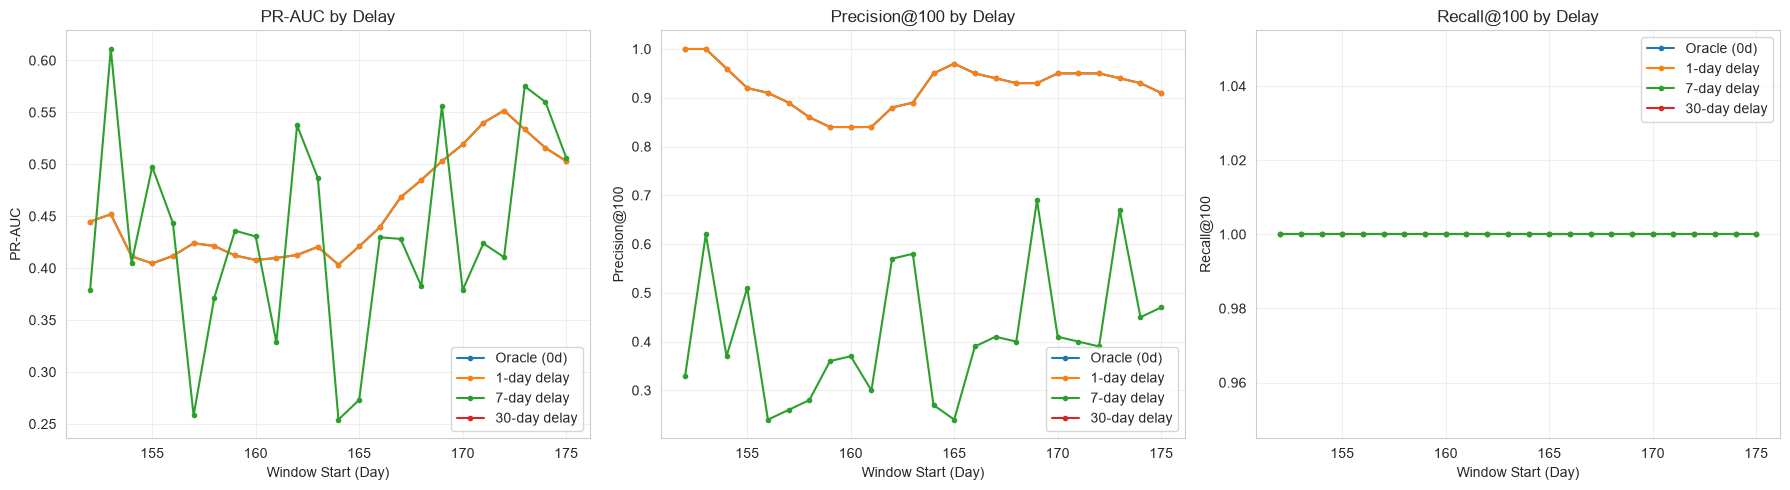

In [36]:
# Run for all delays
all_results = []
for delay in [0, 1, 7, 30]:
    if delay == 0:
        df = evaluate_oracle(model, X_test, y_test, test_ieee, 'TransactionDT')
    else:
        df = evaluate_with_delayed_labels(model, X_test, y_test, test_ieee, 'TransactionDT', delay)
    all_results.append(df)

combined = pd.concat(all_results, ignore_index=True)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for delay in [0, 1, 7, 30]:
    subset = combined[combined['delay_days'] == delay]
    if len(subset) == 0:
        continue
    label = 'Oracle (0d)' if delay == 0 else f'{delay}-day delay'
    axes[0].plot(subset['window_start'], subset['pr_auc'], label=label, marker='o', markersize=3)
    axes[1].plot(subset['window_start'], subset['precision_at_100'], label=label, marker='o', markersize=3)
    axes[2].plot(subset['window_start'], subset['recall_at_100'], label=label, marker='o', markersize=3)

for ax, title in zip(axes, ['PR-AUC', 'Precision@100', 'Recall@100']):
    ax.set_xlabel('Window Start (Day)')
    ax.set_ylabel(title)
    ax.set_title(f'{title} by Delay')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Summary Statistics

In [37]:
summary = combined.groupby('delay_days').agg(
    avg_pr_auc=('pr_auc', 'mean'),
    std_pr_auc=('pr_auc', 'std'),
    avg_p100=('precision_at_100', 'mean'),
    avg_r100=('recall_at_100', 'mean'),
    avg_mature=('n_mature', 'mean'),
).reset_index()

print("=== Delay Impact Summary ===")
display(summary)  # type: ignore[unknown-name]

# Degradation vs oracle
oracle_pr = summary[summary['delay_days'] == 0]['avg_pr_auc'].values[0]
oracle_p100 = summary[summary['delay_days'] == 0]['avg_p100'].values[0]

for _, row in summary.iterrows():
    if row['delay_days'] > 0:
        pr_drop = (oracle_pr - row['avg_pr_auc']) / oracle_pr * 100
        p100_drop = (oracle_p100 - row['avg_p100']) / oracle_p100 * 100
        print(f"{row['delay_days']}d delay: PR-AUC drop {pr_drop:.1f}%, P@100 drop {p100_drop:.1f}%")

=== Delay Impact Summary ===


,delay_days,avg_pr_auc,std_pr_auc,avg_p100,avg_r100,avg_mature
0,0,0.454827,0.050182,0.922083,1.0,20065.208333
1,1,0.454827,0.050182,0.922083,1.0,20065.208333
2,7,0.431817,0.097618,0.415833,1.0,2951.208333
3,30,NaN,NaN,NaN,NaN,0.000000


1.0d delay: PR-AUC drop 0.0%, P@100 drop 0.0%
7.0d delay: PR-AUC drop 5.1%, P@100 drop 54.9%
30.0d delay: PR-AUC drop nan%, P@100 drop nan%


## 7. Save Results

In [38]:
combined.to_csv(REPORTS_DIR / 'delayed_labels_evaluation.csv', index=False)
summary.to_csv(REPORTS_DIR / 'delay_impact_summary.csv', index=False)
print(f"Results saved to {REPORTS_DIR}")

Results saved to ../reports


## 8. Summary & Next Steps

In [39]:
print("""
=== DELAYED LABELS ANALYSIS COMPLETE ===

✅ Simulated 1/7/30-day label delays
✅ Rolling window evaluation with delayed ground truth
✅ Compared vs oracle (0-day delay)
✅ Quantified performance degradation
✅ Results saved to ../reports/

NEXT: Notebook 04_drift_monitoring.ipynb
- PSI/KS drift monitoring on features & scores
- Alert generation and logging
- Drift correlation with performance drops
""")


=== DELAYED LABELS ANALYSIS COMPLETE ===

✅ Simulated 1/7/30-day label delays
✅ Rolling window evaluation with delayed ground truth
✅ Compared vs oracle (0-day delay)
✅ Quantified performance degradation
✅ Results saved to ../reports/

NEXT: Notebook 04_drift_monitoring.ipynb
- PSI/KS drift monitoring on features & scores
- Alert generation and logging
- Drift correlation with performance drops

